# Assignment 2 - Transfer Learning

In this notebook, several transfer learning models are tested for the mushroom classification task. Transfer learning is used because pretrained convolutional neural networks already contain useful low-level and mid-level visual features learned from large image datasets. This often leads to better performance than a custom CNN, especially when the dataset is not extremely large.

Three pretrained backbones are compared in a short validation experiment. The best model is then selected for full training and fine-tuning. Final evaluation is performed using accuracy, macro precision, macro recall, macro F1-score, and a confusion matrix.


## 1. Imports and settings

This section imports the required libraries and defines the main project settings. The notebook assumes that the data preparation step has already been completed and that the dataset has been split into `train`, `val`, and `test` folders inside `data/processed/split`.


In [1]:
from __future__ import annotations

import os
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_ROOT = Path.cwd()
SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "split"

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
STEP3_DIR = ARTIFACTS_DIR / "step3_transfer_learning"
STEP3_MODELS_DIR = STEP3_DIR / "models"
STEP3_REPORTS_DIR = STEP3_DIR / "reports"

for output_dir in [STEP3_MODELS_DIR, STEP3_REPORTS_DIR]:
    output_dir.mkdir(parents=True, exist_ok=True)

TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR = SPLIT_DIR / "val"
TEST_DIR = SPLIT_DIR / "test"

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMAGE_SIZE = (IMG_HEIGHT, IMG_WIDTH)
INPUT_SHAPE = (IMG_HEIGHT, IMG_WIDTH, 3)

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow version:", tf.__version__)
print("Train dir exists:", TRAIN_DIR.exists())
print("Val dir exists:", VAL_DIR.exists())
print("Test dir exists:", TEST_DIR.exists())


TensorFlow version: 2.21.0
Train dir exists: True
Val dir exists: True
Test dir exists: True


## 2. Load datasets

The data is loaded from directory structure. Labels are inferred automatically from folder names. This makes the notebook independent from previous in-memory variables and allows it to run as a standalone file.


In [2]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds_raw.class_names
NUM_CLASSES = len(class_names)

print("Class names:", class_names)
print("Number of classes:", NUM_CLASSES)


Found 4698 files belonging to 9 classes.
Found 1007 files belonging to 9 classes.
Found 1007 files belonging to 9 classes.
Class names: ['Mushroom Agaricus', 'Mushroom Amanita', 'Mushroom Boletus', 'Mushroom Cortinarius', 'Mushroom Entoloma', 'Mushroom Hygrocybe', 'Mushroom Lactarius', 'Mushroom Russula', 'Mushroom Suillus']
Number of classes: 9


## 3. Compute class weights

Class weights are used to reduce the effect of class imbalance during training. These weights can be passed directly to `model.fit()`.


In [3]:
train_labels = []

for _, labels in train_ds_raw:
    train_labels.extend(labels.numpy())

train_labels = np.array(train_labels)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)

class_weights = {i: float(w) for i, w in enumerate(weights)}

print("Class weights:")
print(class_weights)


Class weights:
{0: 2.11336032388664, 1: 0.9942857142857143, 2: 0.6969292389853138, 3: 0.8907849829351536, 4: 2.0551181102362204, 5: 2.3513513513513513, 6: 0.47714808043875684, 7: 0.6492537313432836, 8: 2.4055299539170507}


## 4. Data augmentation

Data augmentation is applied only during training. These transformations increase variability and reduce overfitting.


In [4]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")


## 5. Helper functions

The helper functions below are used for dataset preparation, model compilation, training callbacks, evaluation, and plotting.


In [5]:
def prepare_dataset(dataset: tf.data.Dataset) -> tf.data.Dataset:
    return dataset.prefetch(AUTOTUNE)

train_ds_raw = prepare_dataset(train_ds_raw)
val_ds_raw = prepare_dataset(val_ds_raw)
test_ds_raw = prepare_dataset(test_ds_raw)


def compile_model(model: keras.Model, learning_rate: float = 1e-3) -> keras.Model:
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def create_callbacks(model_name: str, patience_early: int = 4, patience_lr: int = 2):
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=patience_early,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=patience_lr,
            min_lr=1e-6,
            verbose=1
        ),
        ModelCheckpoint(
            filepath=STEP3_MODELS_DIR / f"{model_name}_best.keras",
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]


def plot_training_history(history, title: str):
    history_df = pd.DataFrame(history.history)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history_df["loss"], label="train_loss")
    axes[0].plot(history_df["val_loss"], label="val_loss")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(history_df["accuracy"], label="train_accuracy")
    axes[1].plot(history_df["val_accuracy"], label="val_accuracy")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def get_predictions_and_labels(model: keras.Model, dataset: tf.data.Dataset):
    y_true = []
    y_pred = []
    y_prob = []

    for batch_images, batch_labels in dataset:
        probs = model.predict(batch_images, verbose=0)
        preds = np.argmax(probs, axis=1)

        y_true.extend(batch_labels.numpy())
        y_pred.extend(preds)
        y_prob.extend(probs)

    return np.array(y_true), np.array(y_pred), np.array(y_prob)


def evaluate_model(model: keras.Model, dataset: tf.data.Dataset, class_names: list[str], dataset_name: str):
    y_true, y_pred, y_prob = get_predictions_and_labels(model, dataset)

    acc = accuracy_score(y_true, y_pred)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )

    print(f"{dataset_name} Accuracy: {acc:.4f}")
    print(f"{dataset_name} Precision (macro): {precision_macro:.4f}")
    print(f"{dataset_name} Recall (macro): {recall_macro:.4f}")
    print(f"{dataset_name} F1-score (macro): {f1_macro:.4f}")
    print(f"{dataset_name} Precision (weighted): {precision_weighted:.4f}")
    print(f"{dataset_name} Recall (weighted): {recall_weighted:.4f}")
    print(f"{dataset_name} F1-score (weighted): {f1_weighted:.4f}")
    print()
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    metrics = {
        "accuracy": acc,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "precision_weighted": precision_weighted,
        "recall_weighted": recall_weighted,
        "f1_weighted": f1_weighted
    }

    return metrics, y_true, y_pred, y_prob


def plot_confusion_matrix(y_true, y_pred, class_names: list[str], title: str):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(title)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


## 6. Backbone factory

This function returns both the pretrained backbone and the corresponding preprocessing function. Different pretrained models expect different input normalization rules.


In [6]:
def get_backbone_and_preprocess(backbone_name: str):
    if backbone_name == "MobileNetV2":
        backbone = tf.keras.applications.MobileNetV2(
            include_top=False,
            weights="imagenet",
            input_shape=INPUT_SHAPE
        )
        preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
        return backbone, preprocess_input

    if backbone_name == "ResNet50":
        backbone = tf.keras.applications.ResNet50(
            include_top=False,
            weights="imagenet",
            input_shape=INPUT_SHAPE
        )
        preprocess_input = tf.keras.applications.resnet.preprocess_input
        return backbone, preprocess_input

    if backbone_name == "EfficientNetB0":
        backbone = tf.keras.applications.EfficientNetB0(
            include_top=False,
            weights="imagenet",
            input_shape=INPUT_SHAPE
        )
        preprocess_input = tf.keras.applications.efficientnet.preprocess_input
        return backbone, preprocess_input

    raise ValueError(f"Unknown backbone: {backbone_name}")


## 7. Build transfer learning model

Each transfer learning model uses a pretrained convolutional base, global average pooling, and a custom classification head. The backbone is frozen at first so only the new classification layers are trained.


In [7]:
def build_transfer_model(
    backbone_name: str,
    num_classes: int = NUM_CLASSES,
    dense_units: int = 128,
    dropout_rate: float = 0.30,
    train_backbone: bool = False
) -> keras.Model:
    backbone, preprocess_input = get_backbone_and_preprocess(backbone_name)
    backbone.trainable = train_backbone

    inputs = keras.Input(shape=INPUT_SHAPE)

    x = data_augmentation(inputs)
    x = preprocess_input(x)

    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name=f"tl_{backbone_name}")
    return model


## 8. Quick comparison of backbones

A short experiment is used to compare several pretrained backbones. This stage is meant to identify the most promising backbone before more expensive final training.


This first comparison stage is deliberately lightweight. The purpose is not to obtain the absolute best score immediately, but to make a justified backbone choice.

Testing several pretrained models for a small number of epochs is a sensible trade-off between rigor and computation time. A backbone that already performs well in the early phase is usually a better candidate for full training than a clearly weaker alternative. This gives an evidence-based reason for the final backbone choice instead of selecting one arbitrarily.

In [8]:
backbone_names = ["MobileNetV2", "ResNet50", "EfficientNetB0"]

QUICK_EPOCHS = 6

quick_results = []
quick_histories = {}
quick_models = {}

for backbone_name in backbone_names:
    print("=" * 80)
    print(f"Quick training for backbone: {backbone_name}")
    print("=" * 80)

    model = build_transfer_model(
        backbone_name=backbone_name,
        dense_units=128,
        dropout_rate=0.30,
        train_backbone=False
    )

    model = compile_model(model, learning_rate=1e-3)

    start_time = time.time()

    history = model.fit(
        train_ds_raw,
        validation_data=val_ds_raw,
        epochs=QUICK_EPOCHS,
        class_weight=class_weights,
        callbacks=create_callbacks(model_name=f"{backbone_name}_quick", patience_early=3, patience_lr=2),
        verbose=1
    )

    elapsed = time.time() - start_time

    val_metrics, _, _, _ = evaluate_model(
        model=model,
        dataset=val_ds_raw,
        class_names=class_names,
        dataset_name=f"{backbone_name} Validation"
    )

    quick_results.append({
        "backbone": backbone_name,
        "val_accuracy": val_metrics["accuracy"],
        "val_precision_macro": val_metrics["precision_macro"],
        "val_recall_macro": val_metrics["recall_macro"],
        "val_f1_macro": val_metrics["f1_macro"],
        "training_time_sec": elapsed
    })

    quick_histories[backbone_name] = history
    quick_models[backbone_name] = model


Quick training for backbone: MobileNetV2
Epoch 1/6
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step - accuracy: 0.3469 - loss: 1.8156
Epoch 1: val_loss improved from None to 1.15184, saving model to c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\artifacts\step3_transfer_learning\models\MobileNetV2_quick_best.keras

Epoch 1: finished saving model to c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\artifacts\step3_transfer_learning\models\MobileNetV2_quick_best.keras
147/147 ━━━━━━━━━━━━━━━━━━━━ 53s 337ms/step - accuracy: 0.4381 - loss: 1.5381 - val_accuracy: 0.5829 - val_loss: 1.1518 - learning_rate: 0.0010
Epoch 2/6
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step - accuracy: 0.5871 - loss: 1.1277
Epoch 2: val_loss improved from 1.15184 to 0.99101, saving model to c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\artifacts\step3_transfer_learning\models\MobileNetV2_quick_best.keras

Epoch 2: finished saving model to c:\Users\chupr\Desktop\projects\d

## 9. Compare quick results

The quick experiment results are collected in a table and visualized using a simple bar chart.


In [9]:
quick_results_df = pd.DataFrame(quick_results).sort_values(
    by=["val_f1_macro", "val_accuracy"],
    ascending=False
).reset_index(drop=True)

display(quick_results_df)


,backbone,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,training_time_sec
0,EfficientNetB0,0.755710,0.749005,0.767626,0.746833,384.254456
1,ResNet50,0.729891,0.724972,0.732289,0.709861,786.988023
2,MobileNetV2,0.696127,0.701725,0.665510,0.664693,289.277373


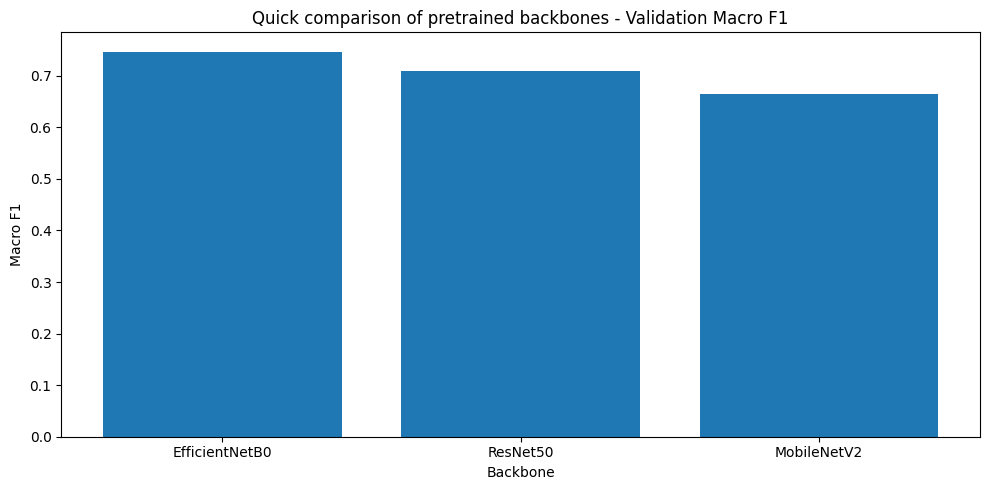

In [10]:
plt.figure(figsize=(10, 5))
plt.bar(quick_results_df["backbone"], quick_results_df["val_f1_macro"])
plt.title("Quick comparison of pretrained backbones - Validation Macro F1")
plt.xlabel("Backbone")
plt.ylabel("Macro F1")
plt.tight_layout()
plt.show()


## 10. Quick training histories

These plots show how each backbone behaved during the short comparison stage.


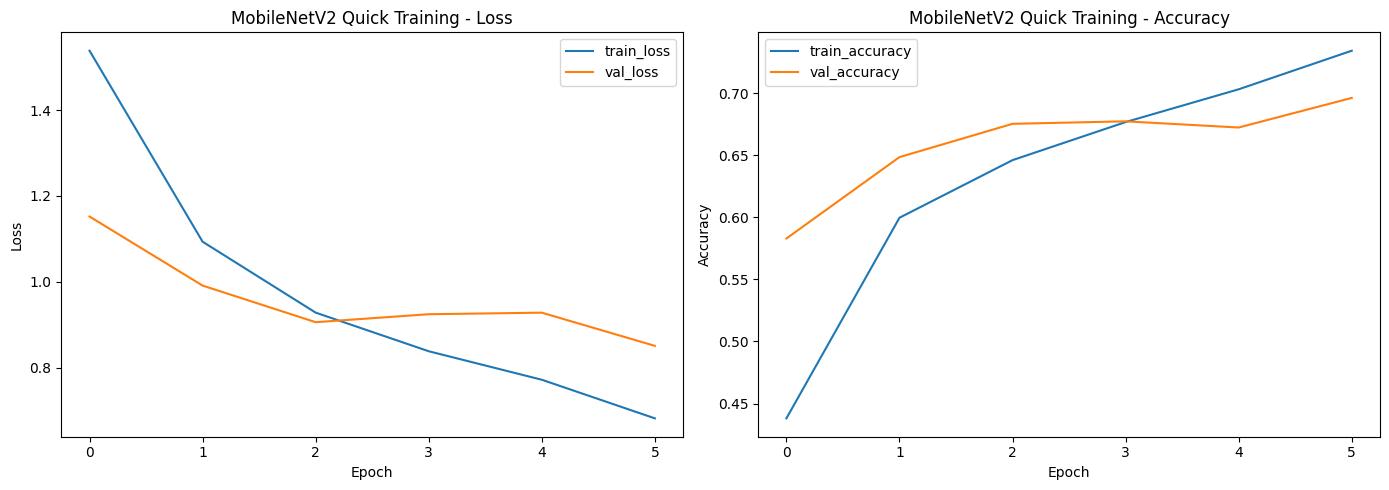

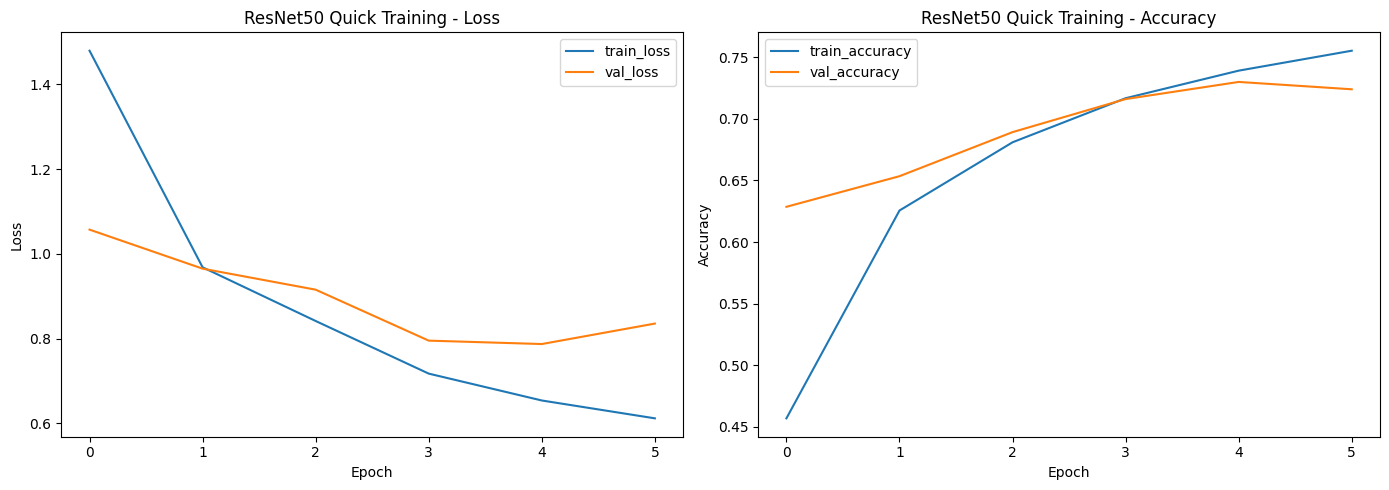

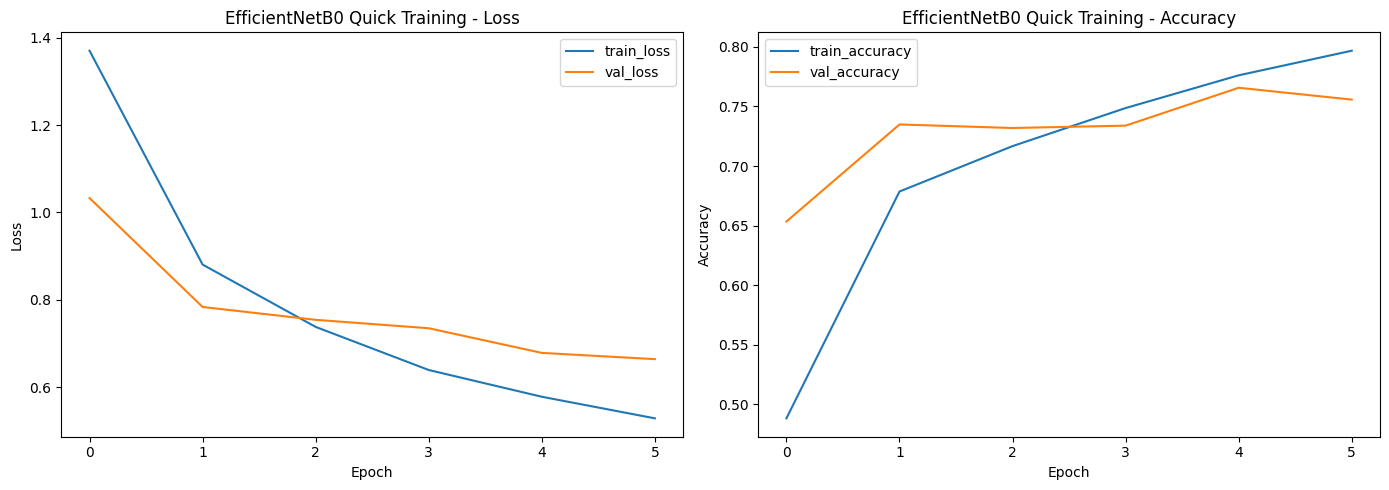

In [11]:
for backbone_name, history in quick_histories.items():
    plot_training_history(history, title=f"{backbone_name} Quick Training")


## 11. Select best backbone

The best backbone is selected based primarily on validation macro F1-score and validation accuracy.


In [12]:
best_backbone = quick_results_df.iloc[0]["backbone"]
print("Best backbone selected:", best_backbone)


Best backbone selected: EfficientNetB0


## 12. Build final model

The best backbone is rebuilt with a slightly larger dense layer and dropout setting for the final training run.


The final transfer learning model keeps the general structure that is standard for image classification:

1. a pretrained convolutional backbone for feature extraction,
2. a global pooling layer to convert feature maps into a compact representation,
3. dropout for regularization,
4. a dense output layer with one score per class.

This design is appropriate here because the pretrained backbone already extracts rich visual features, while the custom classification head adapts those features to the mushroom dataset. The architecture is therefore strong enough to benefit from prior knowledge without becoming unnecessarily complex.

In [13]:
final_model = build_transfer_model(
    backbone_name=best_backbone,
    dense_units=256,
    dropout_rate=0.40,
    train_backbone=False
)

final_model = compile_model(final_model, learning_rate=1e-3)
final_model.summary()


Model: "tl_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 9)              │         2,313 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,379,820 (16.71 MB)

 Trainable params: 330,249 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 13. Stage 1 training: frozen backbone

In the first training stage, the convolutional base remains frozen and only the classification head is trained.


In [14]:
STAGE1_EPOCHS = 10

history_stage1 = final_model.fit(
    train_ds_raw,
    validation_data=val_ds_raw,
    epochs=STAGE1_EPOCHS,
    class_weight=class_weights,
    callbacks=create_callbacks(model_name=f"{best_backbone}_stage1", patience_early=4, patience_lr=2),
    verbose=1
)


Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 344ms/step - accuracy: 0.4296 - loss: 1.5887
Epoch 1: val_loss improved from None to 0.91634, saving model to c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\artifacts\step3_transfer_learning\models\EfficientNetB0_stage1_best.keras

Epoch 1: finished saving model to c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\artifacts\step3_transfer_learning\models\EfficientNetB0_stage1_best.keras
147/147 ━━━━━━━━━━━━━━━━━━━━ 69s 425ms/step - accuracy: 0.5253 - loss: 1.2997 - val_accuracy: 0.6912 - val_loss: 0.9163 - learning_rate: 0.0010
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 344ms/step - accuracy: 0.6838 - loss: 0.8505
Epoch 2: val_loss improved from 0.91634 to 0.78505, saving model to c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\artifacts\step3_transfer_learning\models\EfficientNetB0_stage1_best.keras

Epoch 2: finished saving model to c:\Users\chupr\Desktop\projects\deep-learning-minor-assignme

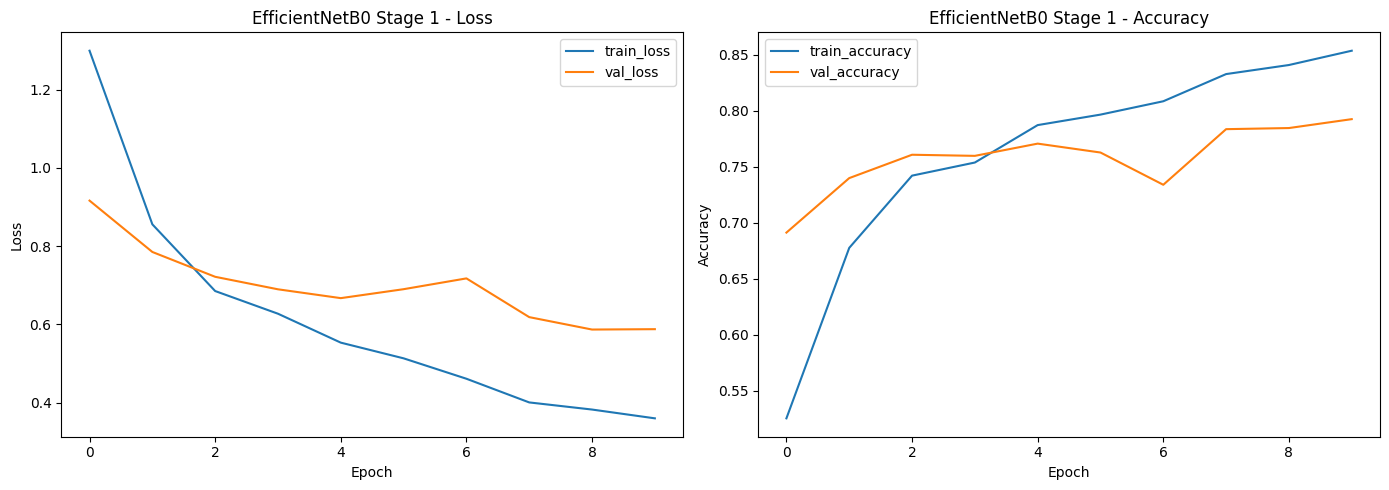

In [15]:
plot_training_history(history_stage1, title=f"{best_backbone} Stage 1")


## 14. Fine-tuning setup

The model is inspected to find the backbone submodel, then the top part of the backbone is unfrozen for fine-tuning.


In [16]:
backbone_layer = None

for layer in final_model.layers:
    if isinstance(layer, keras.Model):
        backbone_layer = layer
        break

print("Backbone layer found:", backbone_layer.name if backbone_layer is not None else "None")


Backbone layer found: data_augmentation


In [17]:
for i, layer in enumerate(final_model.layers):
    print(i, layer.name, type(layer))


0 input_layer_8 <class 'keras.src.layers.core.input_layer.InputLayer'>
1 data_augmentation <class 'keras.src.models.sequential.Sequential'>
2 efficientnetb0 <class 'keras.src.models.functional.Functional'>
3 global_average_pooling2d_3 <class 'keras.src.layers.pooling.global_average_pooling2d.GlobalAveragePooling2D'>
4 dense_6 <class 'keras.src.layers.core.dense.Dense'>
5 dropout_3 <class 'keras.src.layers.regularization.dropout.Dropout'>
6 dense_7 <class 'keras.src.layers.core.dense.Dense'>


In [18]:
backbone = None
for layer in final_model.layers:
    if isinstance(layer, keras.Model) and layer.name.lower() != "data_augmentation":
        backbone = layer
        break

if backbone is None:
    raise ValueError("Backbone model not found inside final_model.")

backbone.trainable = True

fine_tune_at = int(len(backbone.layers) * 0.70)

for layer in backbone.layers[:fine_tune_at]:
    layer.trainable = False

print("Backbone:", backbone.name)
print("Total backbone layers:", len(backbone.layers))
print("Frozen until layer index:", fine_tune_at)


Backbone: efficientnetb0
Total backbone layers: 238
Frozen until layer index: 166


## 15. Recompile for fine-tuning

A much smaller learning rate is used during fine-tuning to avoid damaging pretrained features.


In [19]:
final_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


## 16. Stage 2 training: fine-tuning

Now the top part of the pretrained backbone is trained together with the classification head.


In [20]:
STAGE2_EPOCHS = 12

history_stage2 = final_model.fit(
    train_ds_raw,
    validation_data=val_ds_raw,
    epochs=STAGE2_EPOCHS,
    class_weight=class_weights,
    callbacks=create_callbacks(model_name=f"{best_backbone}_finetune", patience_early=4, patience_lr=2),
    verbose=1
)


Epoch 1/12


147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step - accuracy: 0.5630 - loss: 1.1326
Epoch 1: val_loss improved from None to 0.81595, saving model to c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\artifacts\step3_transfer_learning\models\EfficientNetB0_finetune_best.keras

Epoch 1: finished saving model to c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\artifacts\step3_transfer_learning\models\EfficientNetB0_finetune_best.keras
147/147 ━━━━━━━━━━━━━━━━━━━━ 97s 576ms/step - accuracy: 0.5813 - loss: 1.0865 - val_accuracy: 0.7120 - val_loss: 0.8159 - learning_rate: 1.0000e-05
Epoch 2/12
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step - accuracy: 0.6562 - loss: 0.9121
Epoch 2: val_loss did not improve from 0.81595
147/147 ━━━━━━━━━━━━━━━━━━━━ 82s 557ms/step - accuracy: 0.6490 - loss: 0.8947 - val_accuracy: 0.7011 - val_loss: 0.8476 - learning_rate: 1.0000e-05
Epoch 3/12
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step - accuracy: 0.6899 - loss: 0.8078
Epoch 3: val_loss impr

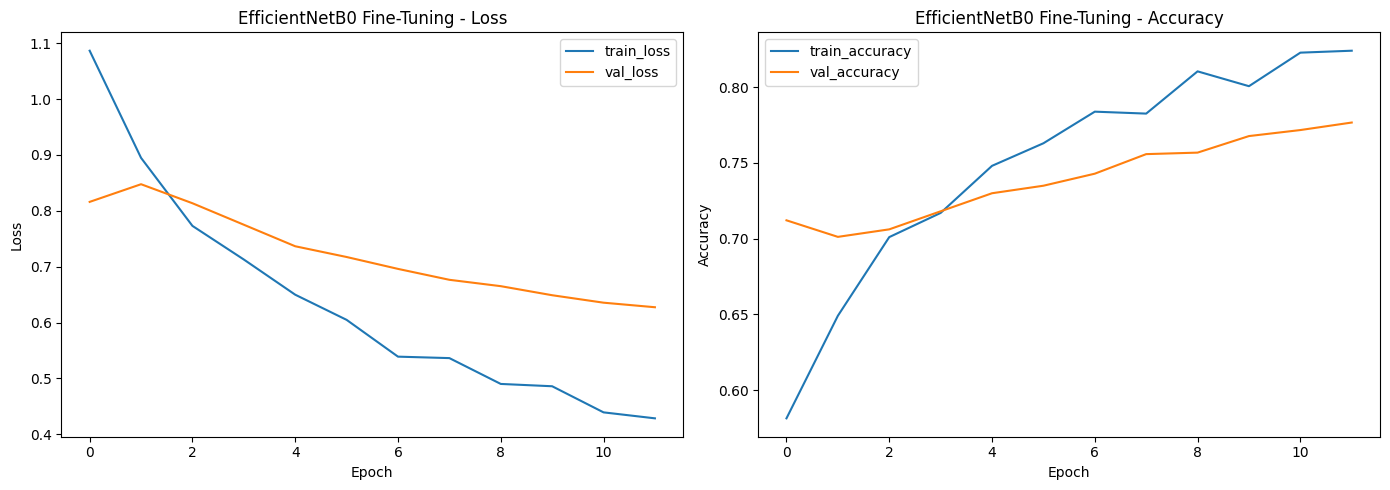

In [21]:
plot_training_history(history_stage2, title=f"{best_backbone} Fine-Tuning")


## 17. Final evaluation

The final model is evaluated on both validation and test sets using multiple classification metrics.


In [22]:
val_metrics, y_val_true, y_val_pred, y_val_prob = evaluate_model(
    model=final_model,
    dataset=val_ds_raw,
    class_names=class_names,
    dataset_name="Final Transfer Model Validation"
)

test_metrics, y_test_true, y_test_pred, y_test_prob = evaluate_model(
    model=final_model,
    dataset=test_ds_raw,
    class_names=class_names,
    dataset_name="Final Transfer Model Test"
)


Final Transfer Model Validation Accuracy: 0.7766
Final Transfer Model Validation Precision (macro): 0.7626
Final Transfer Model Validation Recall (macro): 0.7792
Final Transfer Model Validation F1-score (macro): 0.7676
Final Transfer Model Validation Precision (weighted): 0.7824
Final Transfer Model Validation Recall (weighted): 0.7766
Final Transfer Model Validation F1-score (weighted): 0.7744

                      precision    recall  f1-score   support

   Mushroom Agaricus       0.66      0.77      0.71        53
    Mushroom Amanita       0.76      0.82      0.79       112
    Mushroom Boletus       0.82      0.96      0.88       161
Mushroom Cortinarius       0.71      0.82      0.76       125
   Mushroom Entoloma       0.74      0.71      0.72        55
  Mushroom Hygrocybe       0.93      0.89      0.91        47
  Mushroom Lactarius       0.85      0.64      0.73       235
    Mushroom Russula       0.78      0.76      0.77       172
    Mushroom Suillus       0.61      0.64 

## 18. Confusion matrix

The confusion matrix shows which mushroom classes are predicted correctly and which classes are most often confused.


The confusion matrix is included because overall accuracy alone does not explain *which* classes are difficult. In a multi-class mushroom dataset, some species can look visually similar, and the confusion matrix makes these error patterns visible.

This is useful for two reasons. First, it gives a more honest interpretation of model quality than a single scalar metric. Second, it provides evidence for the comparison between the custom CNN and the transfer learning model, because it shows whether transfer learning reduces confusion between difficult classes.

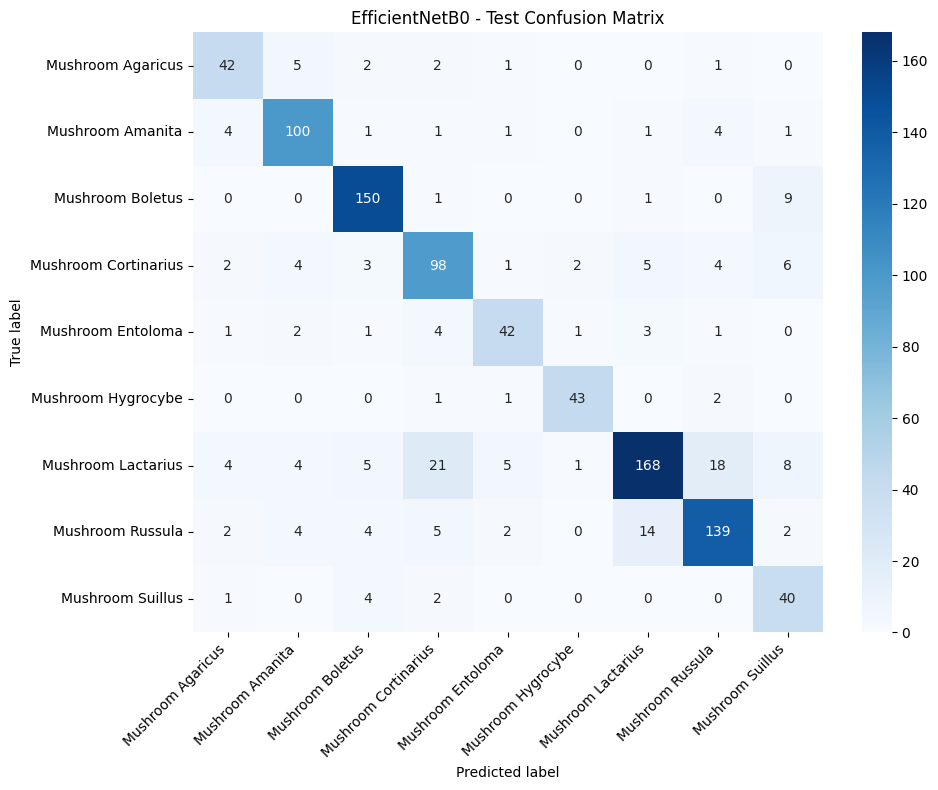

In [23]:
plot_confusion_matrix(
    y_true=y_test_true,
    y_pred=y_test_pred,
    class_names=class_names,
    title=f"{best_backbone} - Test Confusion Matrix"
)


## 19. Save results

The comparison table, final metrics, and final trained model are saved to disk for later use in the report and the final submission.


In [24]:
quick_results_df.to_csv(STEP3_REPORTS_DIR / "transfer_learning_quick_comparison.csv", index=False)

final_metrics_df = pd.DataFrame([
    {
        "model_type": "transfer_learning",
        "backbone": best_backbone,
        "dataset": "validation",
        **val_metrics
    },
    {
        "model_type": "transfer_learning",
        "backbone": best_backbone,
        "dataset": "test",
        **test_metrics
    }
])

display(final_metrics_df)
final_metrics_df.to_csv(STEP3_REPORTS_DIR / "transfer_learning_final_metrics.csv", index=False)

final_model.save(STEP3_MODELS_DIR / f"best_transfer_learning_{best_backbone}.keras")

print("Saved reports to:", STEP3_REPORTS_DIR)
print("Saved models to:", STEP3_MODELS_DIR)


,model_type,backbone,dataset,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,transfer_learning,EfficientNetB0,validation,0.776564,0.762618,0.779191,0.767616,0.782360,0.776564,0.774443
1,transfer_learning,EfficientNetB0,test,0.816286,0.801056,0.827641,0.810835,0.823034,0.816286,0.816533


Saved reports to: c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\artifacts\step3_transfer_learning\reports
Saved models to: c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\artifacts\step3_transfer_learning\models


## 20. Sample predictions

A small batch of predictions is visualized to inspect qualitative model behavior.


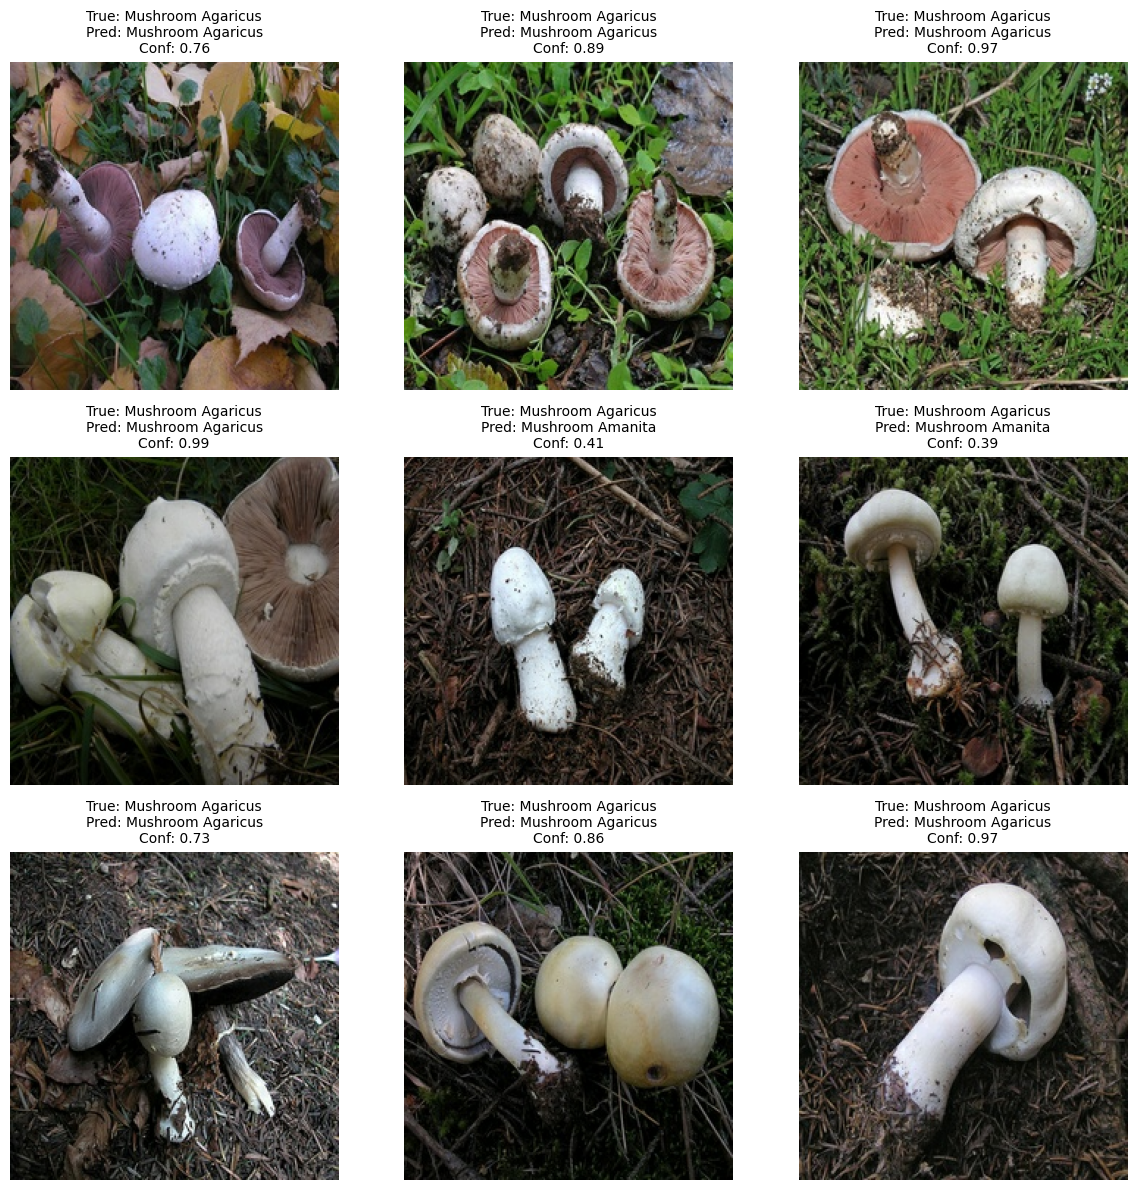

In [25]:
def show_sample_predictions(model: keras.Model, dataset: tf.data.Dataset, class_names: list[str], num_images: int = 9):
    for batch_images, batch_labels in dataset.take(1):
        probs = model.predict(batch_images, verbose=0)
        preds = np.argmax(probs, axis=1)

        plt.figure(figsize=(12, 12))

        for i in range(min(num_images, len(batch_images))):
            ax = plt.subplot(3, 3, i + 1)
            image = batch_images[i].numpy().astype("uint8")
            true_label = class_names[int(batch_labels[i].numpy())]
            pred_label = class_names[int(preds[i])]
            confidence = float(np.max(probs[i]))

            plt.imshow(image)
            plt.title(
                f"True: {true_label}\nPred: {pred_label}\nConf: {confidence:.2f}",
                fontsize=10
            )
            plt.axis("off")

        plt.tight_layout()
        plt.show()

show_sample_predictions(final_model, test_ds_raw, class_names)


## 21. Final summary

This final block provides a compact summary of the transfer learning experiment.


In [26]:
print("TRANSFER LEARNING SUMMARY")
print("-" * 60)
print("Backbones tested:")
for name in backbone_names:
    print("-", name)

print("\nBest backbone:", best_backbone)

print("\nValidation metrics:")
for key, value in val_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nTest metrics:")
for key, value in test_metrics.items():
    print(f"{key}: {value:.4f}")


TRANSFER LEARNING SUMMARY
------------------------------------------------------------
Backbones tested:
- MobileNetV2
- ResNet50
- EfficientNetB0

Best backbone: EfficientNetB0

Validation metrics:
accuracy: 0.7766
precision_macro: 0.7626
recall_macro: 0.7792
f1_macro: 0.7676
precision_weighted: 0.7824
recall_weighted: 0.7766
f1_weighted: 0.7744

Test metrics:
accuracy: 0.8163
precision_macro: 0.8011
recall_macro: 0.8276
f1_macro: 0.8108
precision_weighted: 0.8230
recall_weighted: 0.8163
f1_weighted: 0.8165


## 22. Compare with the custom CNN baseline

The code below loads the saved metrics from the custom CNN notebook, aligns the test metrics, and creates a compact comparison table. This makes the conclusion evidence-based instead of relying on qualitative impressions only.


From a methodological point of view, transfer learning is expected to outperform a custom CNN in this assignment because pretrained backbones start with features learned from very large image datasets. Edges, textures, shapes, and part-based patterns are already encoded before training on the mushroom dataset begins.

The final conclusion should therefore be based on the reported metrics and the confusion matrix, not only on intuition. If the transfer learning model shows better macro-averaged precision, recall, F1-score, and fewer severe confusions between classes, then the result supports the claim that pretrained visual features are beneficial for this dataset.

In [27]:
from pathlib import Path

custom_metrics_path = PROJECT_ROOT / "artifacts" / "step2_custom_cnn" / "reports" / "custom_cnn_final_metrics.csv"
comparison_df = None

if custom_metrics_path.exists():
    custom_metrics_df = pd.read_csv(custom_metrics_path)
    custom_test = custom_metrics_df[custom_metrics_df["dataset"] == "test"].copy()
    transfer_test = pd.DataFrame([{ "model_name": f"transfer_{best_backbone}", **test_metrics }])

    common_cols = [
        col for col in ["model_name", "accuracy", "precision_macro", "recall_macro", "f1_macro"]
        if col in custom_test.columns and col in transfer_test.columns
    ]

    comparison_df = pd.concat([
        custom_test[common_cols],
        transfer_test[common_cols]
    ], ignore_index=True)
    display(comparison_df)
else:
    print("custom_cnn_final_metrics.csv not found. Run the custom CNN notebook first to generate the comparison table.")


,model_name,accuracy,precision_macro,recall_macro,f1_macro
0,custom_cnn_v1,0.396226,0.413240,0.426358,0.389296
1,transfer_EfficientNetB0,0.816286,0.801056,0.827641,0.810835


## 23. Comparison between the Custom CNN and the Transfer Learning Model

The results clearly show that the transfer learning model significantly outperforms the custom CNN trained from scratch. The custom CNN achieved a test accuracy of 0.396 and a macro F1-score of 0.389, while the transfer learning model with an EfficientNetB0 backbone reached a test accuracy of 0.816 and a macro F1-score of 0.811.

This improvement can be explained by the fact that the pretrained backbone already contains visual filters learned from a very large and diverse image dataset. Instead of learning basic visual features from scratch, the network can reuse these representations and focus on adapting them to the mushroom classification task.

The confusion matrices also show a clear difference between the two approaches. The custom CNN struggles to distinguish several mushroom species and produces many cross-class confusions. In contrast, the transfer learning model correctly identifies most classes with high accuracy. Species such as Boletus, Amanita, Russula, and Lactarius are recognized very reliably, while only a small number of misclassifications remain between visually similar species.

Because the dataset contains multiple classes with slightly different sample sizes, the macro F1-score is an especially important metric. The large improvement in macro F1 indicates that the transfer learning model performs better across all classes, not only the most frequent ones.

Overall, the comparison demonstrates that transfer learning provides substantially better generalization for this dataset.


## 24. Conclusion for the Transfer Learning Models

Several pretrained convolutional neural network backbones were evaluated using transfer learning, including MobileNetV2, ResNet50, and EfficientNetB0. A short comparison phase was used to identify the most promising architecture based on validation accuracy and validation macro F1-score. Among the tested models, EfficientNetB0 achieved the best validation performance and was therefore selected for the final model.

The final training was performed in two stages. First, the pretrained convolutional backbone was frozen and only the newly added classification head was trained. In the second stage, the upper layers of the backbone were unfrozen and fine-tuned with a smaller learning rate. This strategy allows the model to gradually adapt pretrained features to the specific characteristics of the mushroom dataset while maintaining training stability.

The final EfficientNetB0 model achieved 0.816 test accuracy and 0.811 macro F1-score, which represents a large improvement compared to the custom CNN baseline. The confusion matrix shows that most mushroom species are classified correctly, with only a limited number of mistakes between visually similar classes.

These results demonstrate that transfer learning is highly effective for this task, especially when the available dataset is relatively small. By leveraging pretrained visual representations, the model is able to extract more discriminative features and achieve substantially better classification performance.
